<a href="https://colab.research.google.com/github/Ahmedsherali/Agentic-AI-LangGraph/blob/main/03_promptChaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U langgraph langchain-google-genai

In [5]:
import os
from google.colab import userdata
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict


os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")


#model = ChatGoogleGenerativeAI(model="gemini-3.8-flash")
#gemini-3.5-flash-lite
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")


class BlogState(TypedDict):
    title: str
    outline: str
    content: str


def create_outline(state: BlogState) -> BlogState:
    title = state['title']
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content
    state['outline'] = outline
    return state




def create_blog(state: BlogState) -> BlogState:
    title = state['title']
    outline = state['outline']
    prompt = f'Write a detailed blog on the title - {title} using the following outline:\n{outline}'
    content = model.invoke(prompt).content
    state['content'] = content
    return state

graph = StateGraph(BlogState)
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)



workflow = graph.compile()
initial_state = {'title': 'Rise of AI '}
final_state = workflow.invoke(initial_state)




print("------------------- OUTLINE ---")
print(final_state['outline'])
print("\n------------------- BLOG CONTENT ---\n")
print(final_state['content'])

------------------- OUTLINE ---
[{'type': 'text', 'text': 'Here is a comprehensive and detailed blog outline on the topic **"The Rise of AI."** \n\nThis outline is structured to engage a general-to-professional audience, covering the history, current landscape, challenges, and future of Artificial Intelligence.\n\n---\n\n# Blog Title Options:\n*   *The Rise of AI: How Artificial Intelligence is Reshaping Our World*\n*   *From Sci-Fi to Reality: The Unstoppable Rise of Artificial Intelligence*\n*   *Living in the Age of AI: What the Rise of Artificial Intelligence Means for You*\n\n---\n\n## I. Introduction\n*   **Hook:** Start with a relatable scenario or a striking statistic. (e.g., *“Thirty years ago, AI was a concept confined to science fiction movies. Today, it writes our emails, diagnoses diseases, and drives our cars.”*)\n*   **Definition:** Briefly define Artificial Intelligence (narrow AI vs. General AI) in simple terms.\n*   **The Shift:** Explain *why* AI is rising right now 

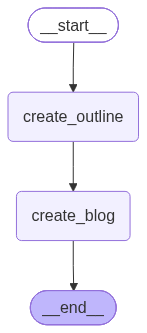

In [6]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())